In [1]:
%load_ext jupyter_black

# Index


<div class="alert alert-block alert-info" style="margin-top: 20px">

<font size = 4>
1. <a href="#Imports">Imports</a><br>
2. <a href="#Data-preparation">Data preparation</a><br>
3. <a href="#Model-training">Model training</a><br>
4. <a href="#External-validation">External validation</a><br>
5. <a href="#SHAP-analysis">SHAP analysis</a><br>

</font>
</div>

# Imports

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from catboost import CatBoostClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    recall_score,
)
from sklearn.preprocessing import StandardScaler

sns.set(style="white", color_codes=True, palette="colorblind", font_scale=1)

# Data preparation

In [3]:
dilirank2 = pd.read_excel(
    "../data/Supporting Information 2.xlsx",
    sheet_name="Table S5 - DILIrank 2.0",
)

dilirank2.shape

(838, 139)

In [4]:
dilirank2.drop(
    columns=[
        "LTKBID",
        "SMILES",
        "InChIKey",
        # "Compound Name",
        "DILI Concern",
        "Drug Formulation",
        "Canonical SMILES",
        "Canonical InChIKey",
        "Stereoisomerism",
        "Tautomers at pH7.4 above 10% abundance",
        "Protomers at pH7.4 above 10% abundance",
        # "Normalised pH7.4 SMILES",
        # "Normalised pH7.4 InChIKey",
        "Ionic Character",
        # "DILI Class",
    ],
    inplace=True,
)

dilirank2.sort_values(by=["Normalised pH7.4 InChIKey"], inplace=True)

dilirank2.shape

(838, 128)

In [5]:
training_set = dilirank2[dilirank2["Set"] == "training"]
training_set.reset_index(drop=True, inplace=True)
training_set = training_set.drop(columns=["Set"]).copy()

test_set = dilirank2[dilirank2["Set"] == "test"]
test_set.reset_index(drop=True, inplace=True)
test_set = test_set.drop(columns=["Set"]).copy()

training_set.shape, test_set.shape

((698, 127), (140, 127))

In [6]:
volsurf_cols = [
    "V",
    "S",
    "R",
    "G",
    "d",
    "W1",
    "W2",
    "W3",
    "W4",
    "W5",
    "W6",
    "W7",
    "W8",
    "D1",
    "D2",
    "D3",
    "D4",
    "D5",
    "D6",
    "D7",
    "D8",
    "WO1",
    "WO2",
    "WO3",
    "WO4",
    "WO5",
    "WO6",
    "WN1",
    "WN2",
    "WN3",
    "WN4",
    "WN5",
    "WN6",
    "IW1",
    "IW2",
    "IW3",
    "IW4",
    "CW1",
    "CW2",
    "CW4",
    "CW5",
    "CW6",
    "CW7",
    "CW8",
    "ID1",
    "ID2",
    "ID3",
    "ID4",
    "CD1",
    "CD2",
    "CD3",
    "CD4",
    "CD5",
    "CD6",
    "CD7",
    "CD8",
    "HL1",
    "HL2",
    "A",
    "CP",
    "POL",
    "MW",
    "FLEX",
    "FLEX_RB",
    "NCC",
    "DIFF",
    "SE",
    "SE0",
    "SE1",
    "LOGP n-Oct",
    "LOGP c-Hex",
    "PSA",
    "HSA",
    "PSAR",
    "PHSAR",
    "LgD5",
    "LgD6",
    "LgD7",
    "LgD7.5",
    "LgD8",
    "LgD9",
    "LgD10",
    "AUS7.4",
    "%FU4",
    "%FU5",
    "%FU6",
    "%FU7",
    "%FU8",
    "%FU9",
    "%FU10",
    "SOLY",
    "LgS3",
    "LgS4",
    "LgS5",
    "LgS6",
    "LgS7",
    "LgS7.5",
    "LgS8",
    "LgS9",
    "LgS10",
    "LgS11",
    "MpKaA",
    "mpKaB",
    "PB",
    "VD",
    "CACO2",
    "SKIN",
    "LgBB",
    "MetStab",
    "HTSflag",
    "C1",
    "C2",
    "C3",
    "C4",
    "C5",
    "P1",
    "P2",
    "P3",
    "P4",
    "P5",
    "EMDIF",
    "EMDIS",
]

In [7]:
scaler = StandardScaler()

X_training = training_set.loc[:, volsurf_cols]
X_test = test_set.loc[:, volsurf_cols]

X_training_scaled = scaler.fit_transform(X_training)
X_test_scaled = scaler.transform(X_test)

In [8]:
y_training = training_set["DILI Class"].tolist()

y_test = test_set["DILI Class"].tolist()

# Model training

In [9]:
model = CatBoostClassifier(
    loss_function="MultiClass",
    eval_metric="TotalF1",
    iterations=600,
    depth=10,
    learning_rate=0.05,
    l2_leaf_reg=10,
    random_strength=1,
    auto_class_weights="Balanced",
    verbose=False,
    random_seed=0,
)

In [10]:
model.fit(X_training_scaled, y_training)

# External validation

In [11]:
y_pred_ext = model.predict(X_test_scaled)
proba_ext = model.predict_proba(X_test_scaled)

print(classification_report(y_test, y_pred_ext, digits=2))

              precision    recall  f1-score   support

           1       0.79      0.24      0.37        95
           2       0.15      0.33      0.21        24
           3       0.24      0.67      0.35        21

    accuracy                           0.32       140
   macro avg       0.40      0.41      0.31       140
weighted avg       0.60      0.32      0.34       140



<Axes: xlabel='Metric', ylabel='Value'>

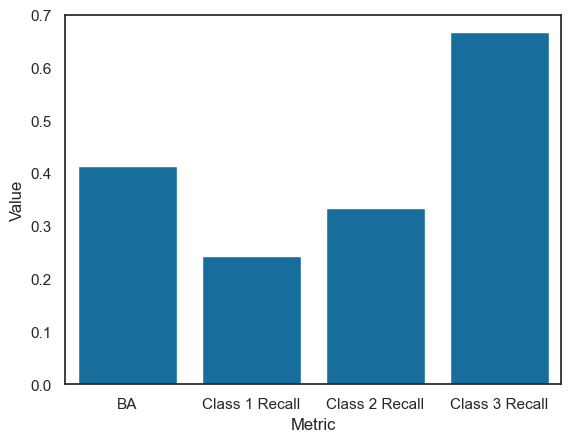

In [12]:
sns.barplot(
    pd.DataFrame(
        {
            "Metric": ["BA", "Class 1 Recall", "Class 2 Recall", "Class 3 Recall"],
            "Value": [balanced_accuracy_score(y_test, y_pred_ext)]
            + recall_score(y_test, y_pred_ext, average=None).tolist(),
        }
    ),
    x="Metric",
    y="Value",
)

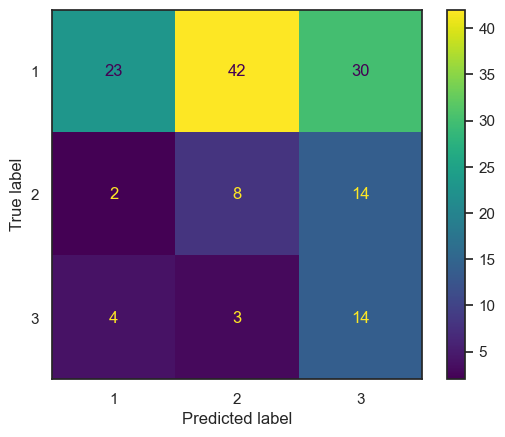

In [13]:
cm = confusion_matrix(
    y_true=y_test,
    y_pred=y_pred_ext,
    labels=[1, 2, 3],
)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[1, 2, 3])
disp.plot()

# SHAP analysis

In [14]:
import numpy as np
import shap

from catboost import Pool
from matplotlib.gridspec import GridSpec
from matplotlib.colors import to_rgb
from matplotlib.lines import Line2D

# Shared settings for the SHAP figures
POS_COLOR = "#D55E00"  # increases the class-3 output
NEG_COLOR = "#0072B2"  # decreases the class-3 output

# Orange and blue are reserved for the DIRECTION of a SHAP contribution,
# so the beeswarm encodes descriptor VALUE on an unrelated sequential map
VALUE_CMAP = "viridis"
TOP_N_GLOBAL = 20
TOP_N_LOCAL = 10

In [15]:
sv = model.get_feature_importance(Pool(X_test_scaled, y_test), type="ShapValues")

class3_idx = list(model.classes_).index(3)

shap_class3 = sv[:, class3_idx, :-1]

print("SHAP matrix shape:", shap_class3.shape)
print("Expected shape:", (len(X_test_scaled), len(volsurf_cols)))

SHAP matrix shape: (140, 122)
Expected shape: (140, 122)


In [16]:
global_importance = pd.DataFrame(
    {
        "Descriptor": volsurf_cols,
        "Mean absolute SHAP": np.abs(shap_class3).mean(axis=0),
    }
)

global_importance = global_importance.sort_values(
    "Mean absolute SHAP", ascending=False
).reset_index(drop=True)

display(global_importance.head(20))

,Descriptor,Mean absolute SHAP
0,C2,0.059099
1,IW4,0.039277
2,C4,0.036595
3,IW3,0.033929
4,CD6,0.029192
5,LgD5,0.029135
6,CD7,0.028578
7,%FU5,0.028466
8,CD5,0.028453
9,ID3,0.028031


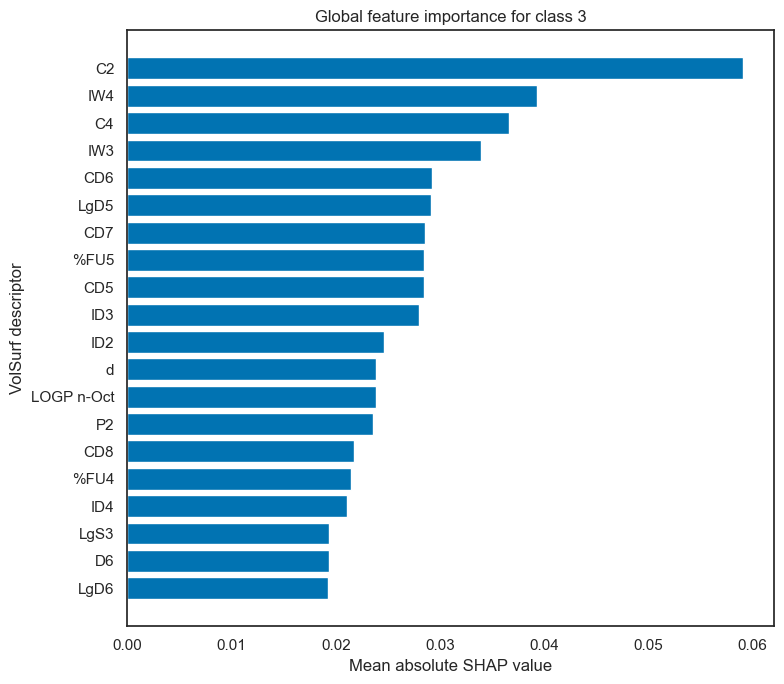

In [17]:
top_n = 20
plot_data = global_importance.head(top_n).sort_values(
    "Mean absolute SHAP", ascending=True
)

fig, ax = plt.subplots(figsize=(8, 7))

ax.barh(plot_data["Descriptor"], plot_data["Mean absolute SHAP"])

ax.set_xlabel("Mean absolute SHAP value")
ax.set_ylabel("VolSurf descriptor")
ax.set_title("Global feature importance for class 3")
plt.tight_layout()
plt.show()

In [18]:
X_test_df = pd.DataFrame(np.asarray(X_test_scaled), columns=volsurf_cols)

print(X_test_df.shape)

(140, 122)


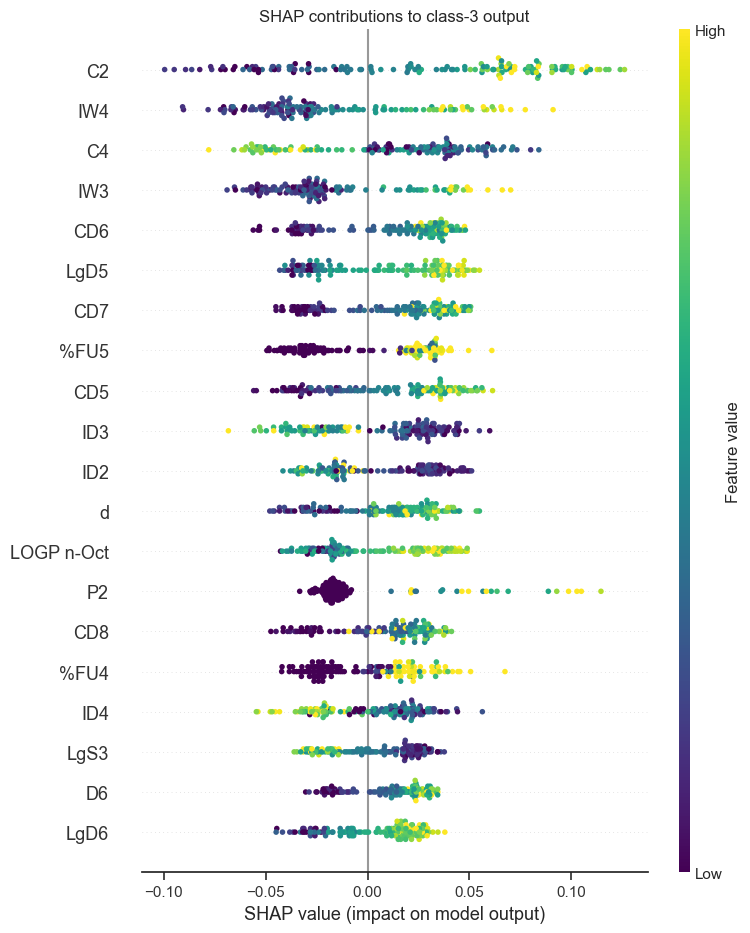

In [19]:
# Keep only the top descriptors so that SHAP does not append the
# "Sum of N other features" row at the bottom of the plot
mean_abs_shap = np.abs(shap_class3).mean(axis=0)
top_idx = np.argsort(mean_abs_shap)[::-1][:TOP_N_GLOBAL]
top_names = [volsurf_cols[i] for i in top_idx]

shap.summary_plot(
    shap_class3[:, top_idx],
    X_test_df.iloc[:, top_idx],
    feature_names=top_names,
    max_display=TOP_N_GLOBAL,
    plot_type="dot",
    cmap=plt.get_cmap(VALUE_CMAP),
    show=False,
)

plt.title("SHAP contributions to class-3 output")
plt.tight_layout()

In [20]:
def find_compound(name):
    matches = np.flatnonzero(
        test_set["Compound Name"]
        .astype(str)
        .str.contains(name, case=False, regex=False, na=False)
        .to_numpy()
    )

    if len(matches) == 0:
        raise ValueError(f"Could not find {name!r} in test_set.")

    if len(matches) > 1:
        print(f"Multiple matches for {name}; using the first.")

    return int(matches[0])


regorafenib_idx = find_compound("regorafenib")
fingolimod_idx = find_compound("fingolimod")

print("Regorafenib row:", regorafenib_idx)
print("Fingolimod row:", fingolimod_idx)

Regorafenib row: 27
Fingolimod row: 49


In [21]:
def plot_compound_shap(ax, idx, compound_name, panel_letter):
    """Plot the largest absolute SHAP contributions for one compound."""

    values = shap_class3[idx]
    order = np.argsort(np.abs(values))[-TOP_N_LOCAL:]

    names = [volsurf_cols[i] for i in order]
    contributions = values[order]
    colors = [POS_COLOR if value > 0 else NEG_COLOR for value in contributions]

    ax.barh(names, contributions, color=colors, height=0.7)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("SHAP contribution to class 3", fontsize=11)
    ax.tick_params(axis="both", labelsize=10)
    ax.grid(axis="x", linestyle=":", alpha=0.35)
    ax.set_axisbelow(True)

    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)

    # Prediction information, as a secondary line under the panel title
    predicted_class = int(np.asarray(y_pred_ext).ravel()[idx])
    true_class = int(np.asarray(y_test).ravel()[idx])

    ax.set_title(
        f"({panel_letter}) {compound_name}",
        loc="left",
        fontsize=13,
        fontweight="bold",
        pad=24,
    )
    ax.text(
        0,
        1.02,
        f"true class {true_class}   \u2022   predicted class {predicted_class}",
        transform=ax.transAxes,
        fontsize=10,
        color="0.3",
        va="bottom",
    )

    # Leave a little room so the bars do not touch the frame
    low, high = ax.get_xlim()
    pad = 0.08 * (high - low)
    ax.set_xlim(low - pad if low < 0 else low, high + pad)

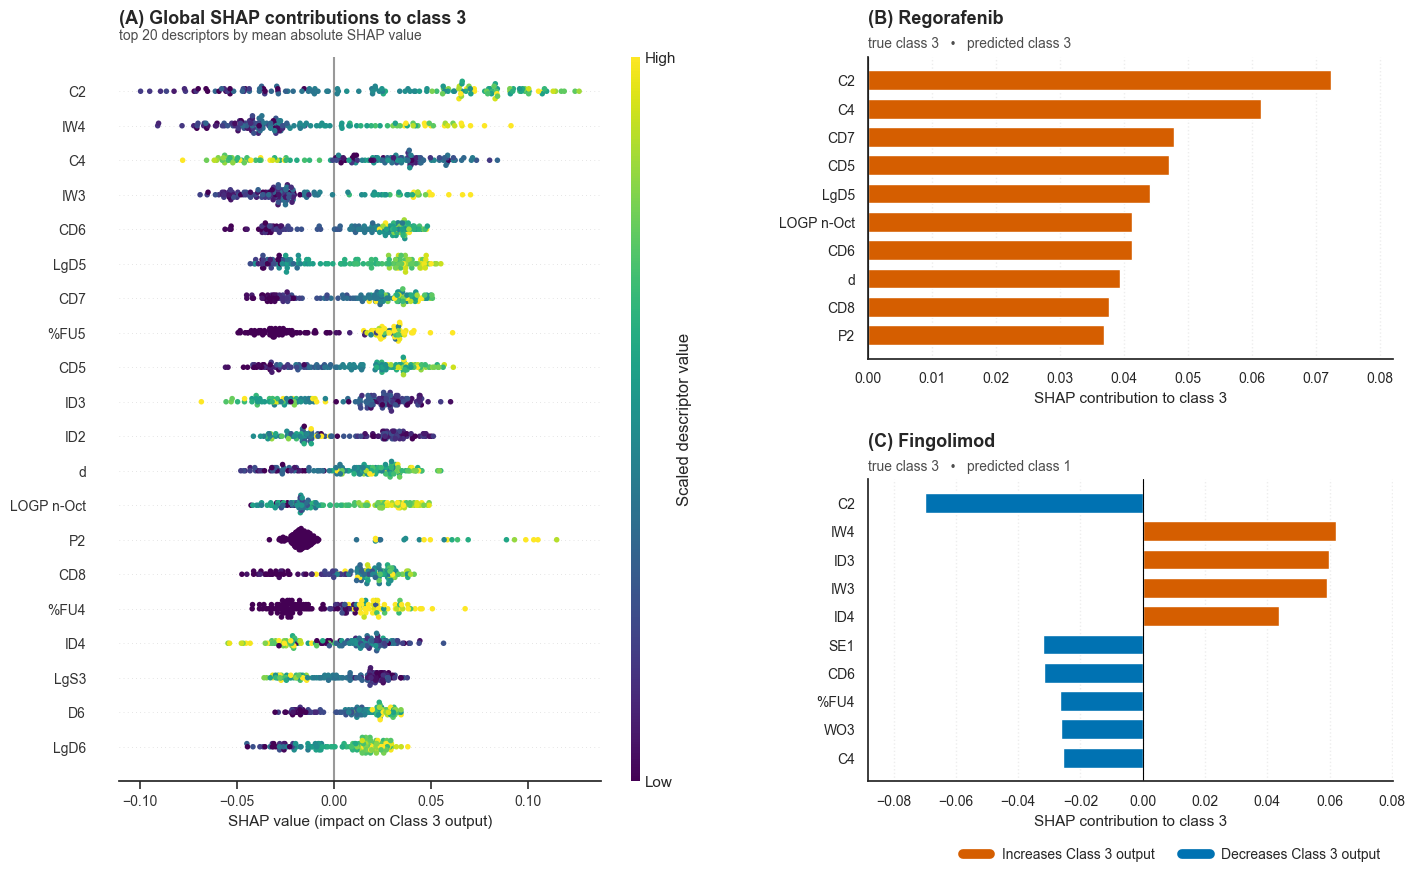

In [22]:
fig = plt.figure(figsize=(14, 9))

gs = GridSpec(
    nrows=2,
    ncols=2,
    figure=fig,
    width_ratios=[1.15, 1.00],
    height_ratios=[1, 1],
    left=0.075,
    right=0.985,
    top=0.92,
    bottom=0.115,
    wspace=0.26,
    hspace=0.40,
)

# Panel A: global beeswarm, spanning both rows on the left.
# Only the top descriptors are passed to SHAP, so that no
# "Sum of N other features" row is added and the x-axis is not
# dominated by that aggregate.
ax_global = fig.add_subplot(gs[:, 0])

mean_abs_shap = np.abs(shap_class3).mean(axis=0)
top_idx = np.argsort(mean_abs_shap)[::-1][:TOP_N_GLOBAL]

explanation = shap.Explanation(
    values=shap_class3[:, top_idx],
    data=X_test_df.to_numpy()[:, top_idx],
    feature_names=[volsurf_cols[i] for i in top_idx],
)

shap.plots.beeswarm(
    explanation,
    max_display=TOP_N_GLOBAL,
    ax=ax_global,
    show=False,
    plot_size=None,
    color=plt.get_cmap(VALUE_CMAP),
    color_bar_label="Scaled descriptor value",
)

ax_global.set_title(
    "(A) Global SHAP contributions to class 3",
    loc="left",
    fontsize=13,
    fontweight="bold",
    pad=24,
)
ax_global.text(
    0,
    1.02,
    f"top {TOP_N_GLOBAL} descriptors by mean absolute SHAP value",
    transform=ax_global.transAxes,
    fontsize=10,
    color="0.3",
    va="bottom",
)
ax_global.set_xlabel("SHAP value (impact on Class 3 output)", fontsize=11)
ax_global.tick_params(labelsize=10)

# Panel B: Regorafenib, top right
ax_reg = fig.add_subplot(gs[0, 1])

plot_compound_shap(ax_reg, regorafenib_idx, "Regorafenib", "B")

# Panel C: Fingolimod, bottom right
ax_fing = fig.add_subplot(gs[1, 1])

plot_compound_shap(ax_fing, fingolimod_idx, "Fingolimod", "C")

# Shared colour key for panels B and C
handles = [
    Line2D([0], [0], color=POS_COLOR, lw=7),
    Line2D([0], [0], color=NEG_COLOR, lw=7),
]

fig.legend(
    handles,
    [
        "Increases Class 3 output",
        "Decreases Class 3 output",
    ],
    loc="lower right",
    bbox_to_anchor=(0.985, 0.012),
    ncol=2,
    frameon=False,
    fontsize=10,
)

# fig.savefig(
#     "shap_global_and_compound_panels.png",
#     dpi=300,
#     bbox_inches="tight",
#     facecolor="white",
# )

### <span style="color:black"> <b><center> End of the notebook </span></b></center> <a id='test_configuration_file'></a>
***
!-- [Back to Index](#Index) -->